# 03 ROI 코드 리뷰 (Jupyter)

1일차 03코드 Jupyter로 코드 리뷰 방법 — **BLOCK 1 (STEP 1~5)**

입력(Input)과 이미지 읽기 오류 확인

### STEP 1. 라이브러리를 가져옵니다

`Path`는 파일 경로를 다루고, `cv2`는 이미지를 읽고 처리합니다. `plt`는 Jupyter 화면에 이미지를 표시할 때 사용합니다. 여기서는 아직 화면에 결과가 나타나지 않는 것이 정상입니다.

In [1]:
### BLOCK 1 — 입력(Input)과 이미지 읽기 오류 확인
### STEP 1: 라이브러리 준비
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

### STEP 2. 현재 작업 폴더를 확인합니다

출력이 프로젝트 최상위인 `.../subject9_machinevision`인지 확인합니다. 다르면 상대경로로 파일을 찾지 못할 수 있습니다.

In [2]:
### STEP 2: 상대경로의 기준 확인
print("현재 작업 폴더:", Path.cwd())

현재 작업 폴더: /home/user1/ai_vision/subject9_machinevision


### STEP 3. 입력 경로와 저장 폴더 경로를 정합니다

`False`라면 경로와 파일명을 먼저 확인하세요. 여기서는 저장 폴더의 경로만 정하고 아직 만들지 않습니다.

In [3]:
### STEP 3: 경로 설정
image_path = Path("samples/sample01.jpg")
output_dir = Path("outputs/roi")
print("입력 파일:", image_path)
print("파일 존재:", image_path.is_file())

입력 파일: samples/sample01.jpg
파일 존재: True


### STEP 4. 이미지를 읽고 자료형을 확인합니다

정상이라면 `numpy.ndarray`가 출력됩니다. 읽기 실패 시 `NoneType`이 나올 수 있으므로 다음 셀에서 검사합니다.

In [4]:
### STEP 4: 이미지 입력
image = cv2.imread(str(image_path))
print("읽기 결과 자료형:", type(image))

읽기 결과 자료형: <class 'numpy.ndarray'>


### STEP 5. 이미지 읽기 실패를 검사합니다

`image_path.is_file()`이 `True`여도 이미지가 손상되었거나 지원하지 않는 파일이면 `cv2.imread()`가 실패할 수 있습니다. 파일 존재 확인과 `image is None` 검사는 서로 다른 목적입니다.

In [5]:
### STEP 5: 예외 처리
if image is None:
    raise FileNotFoundError(f"이미지 읽기 실패: {image_path}")
print("이미지 읽기 성공")

이미지 읽기 성공


# BLOCK 2 — 이미지 구조 확인(Input Analysis)

### STEP 6. 배열의 크기와 자료형을 확인합니다

컬러 이미지의 `shape`는 일반적으로 `(세로, 가로, 채널)`입니다. `image[0, 0]`은 좌측 상단 픽셀의 색상값입니다. 출력 숫자는 이미지마다 달라집니다.

In [6]:
### BLOCK 2 — 입력 이미지 분석
### STEP 6: 배열 구조 확인
print("Shape:", image.shape)
print("Dtype:", image.dtype)
print("첫 픽셀(BGR):", image[0, 0])

Shape: (640, 640, 3)
Dtype: uint8
첫 픽셀(BGR): [24 24 24]


### STEP 7. Height와 Width를 분리합니다

NumPy 이미지 배열의 행은 **y(세로)**, 열은 **x(가로)**에 해당합니다.

In [7]:
### STEP 7: 이미지 크기 분리
height, width = image.shape[:2]
print("Height:", height)
print("Width :", width)

Height: 640
Width : 640


### STEP 8. 이미지의 색상 순서를 변환합니다

색상 순서만 바꾸었으므로 이미지의 가로·세로 크기는 그대로입니다.

In [8]:
### STEP 8: OpenCV BGR → Matplotlib RGB
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
print("RGB Shape:", rgb_image.shape)

RGB Shape: (640, 640, 3)


### STEP 9. 원본 이미지를 화면에 표시합니다

**확인 질문:** 병뚜껑은 원본의 어느 쪽에 있나요? 주변에 불필요한 배경이 얼마나 있나요?

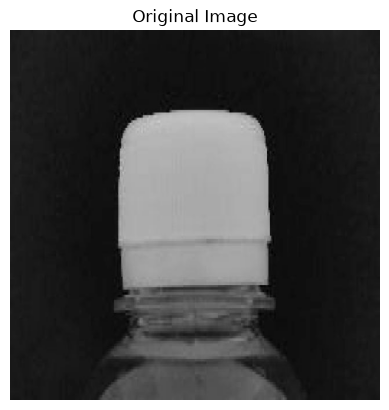

In [9]:
### STEP 9: 원본 시각화
plt.imshow(rgb_image)
plt.title("Original Image")
plt.axis("off")
plt.show()

# BLOCK 3 — 첫 번째 ROI 좌표 설정과 검증(Setting + Validation)

### STEP 10. 눈대중으로 첫 번째 ROI 좌표를 정합니다

`(x1, y1)`은 왼쪽 위, `(x2, y2)`는 오른쪽 아래입니다. **이 값은 원본 교재의 예시로 실제 사진에 맞춘 정답 좌표가 아닙니다.**

In [10]:
### BLOCK 3 — 첫 ROI 좌표 설정과 검증
### STEP 10: 처음 시도하는 좌표(교재의 원본 예시)
x1, y1 = 200, 100
x2, y2 = 700, 500
print("첫 ROI 좌표:", (x1, y1, x2, y2))

첫 ROI 좌표: (200, 100, 700, 500)


### STEP 11. `min()`과 `max()`를 작은 예제로 확인합니다

`min()`은 큰 좌표가 이미지 너비를 초과하지 않게 하고, `max()`는 음수 좌표가 0보다 작아지지 않게 합니다. 여기서 `640`은 **함수 설명용 숫자**이고, 실제 보정에는 이미지의 `width`, `height`를 사용합니다.

In [11]:
### STEP 11: 좌표 보정 원리 연습
print("min(700, 640):", min(700, 640))
print("max(0, -20):", max(0, -20))

min(700, 640): 640
max(0, -20): 0


### STEP 12. 첫 ROI 좌표를 이미지 범위 안으로 보정합니다

**확인 질문:** 이미지 너비가 640인데 `x2=700`이었다면 어떻게 될까요? 현재 이미지가 640보다 작다면 나오는 값은 또 달라집니다.

In [12]:
### STEP 12: x좌표 보정
x1 = max(0, min(x1, width))
x2 = max(0, min(x2, width))
print("보정한 x:", x1, x2)

보정한 x: 200 640


In [13]:
### STEP 12-2: y좌표 보정
y1 = max(0, min(y1, height))
y2 = max(0, min(y2, height))
print("보정한 y:", y1, y2)

보정한 y: 100 500


### STEP 13. 좌표 순서가 잘못되지 않았는지 확인합니다

둘 중 하나라도 `True`라면 정상적인 ROI가 만들어지지 않습니다.

- `x1 >= x2` : 왼쪽 좌표가 오른쪽 좌표보다 크거나 같은가?
- `y1 >= y2` : 위쪽 좌표가 아래쪽 좌표보다 크거나 같은가?

두 조건 모두 `False`이면 정상적인 ROI 좌표이며, 하나라도 `True`이면 ROI를 올바르게 자를 수 없으므로 오류 처리해야 합니다.

In [14]:
### STEP 13: 조건식 확인
print("x1 >= x2:", x1 >= x2)
print("y1 >= y2:", y1 >= y2)

x1 >= x2: False
y1 >= y2: False


### STEP 14. 잘못된 좌표라면 오류를 발생시킵니다

좌표가 범위 안에 있더라도 시작점이 끝점보다 뒤에 있을 수 있습니다. 따라서 **범위 보정 후에도 순서 검증이 필요**합니다. 여기서 오류가 발생하면 실제 이미지를 보고 STEP 10의 좌표를 다시 정하세요.

In [15]:
### STEP 14: 예외 처리
if x1 >= x2 or y1 >= y2:
    raise ValueError(f"잘못된 ROI 좌표: {(x1, y1, x2, y2)}")
print("첫 ROI 좌표 검증 통과")

첫 ROI 좌표 검증 통과


# BLOCK 4 — 첫 번째 ROI 자르기(Processing ①)

### STEP 15. NumPy 배열에서 ROI를 추출합니다

**핵심:** 좌표를 쓸 때는 `(x, y)`라고 말하지만, NumPy 슬라이싱은 `image[y1:y2, x1:x2]`입니다. 끝 인덱스는 **포함되지 않으므로**, 가로 길이는 `x2-x1`, 세로 길이는 `y2-y1`입니다.

In [16]:
### BLOCK 4 — 첫 ROI 추출
### STEP 15: 이미지 슬라이싱
roi = image[y1:y2, x1:x2]
print("원본 Shape:", image.shape)
print("ROI Shape:", roi.shape)

원본 Shape: (640, 640, 3)
ROI Shape: (400, 440, 3)


### STEP 16. 처음 잘라낸 ROI를 나중에 비교할 수 있도록 기억합니다

이 셀은 처음의 ROI와 수정 후 ROI를 비교하기 위해 Jupyter에서 추가한 코드입니다. 원본 `.py`에는 꼭 필요한 단계가 아닙니다.

In [17]:
### STEP 16: 첫 ROI 보존(리뷰 전용)
roi_first = roi.copy()
print("첫 ROI Shape:", roi_first.shape)

첫 ROI Shape: (400, 440, 3)


### STEP 17. 처음 잘라낸 ROI를 화면으로 봅니다

**결과 확인:** 병뚜껑이 충분히 포함되었나요? 너무 왼쪽에 있거나, 불필요한 배경이 많거나, 일부가 잘리지 않았나요? 잘못 보였다면 다음 블록에서 **그리드**를 이용해 수정합니다.

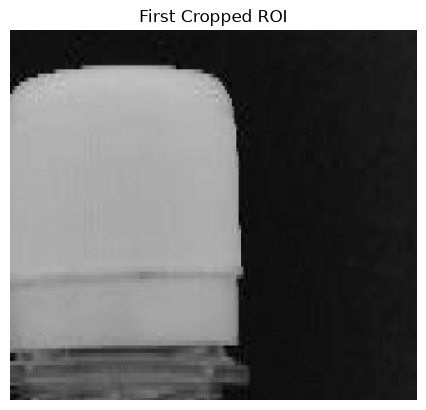

In [18]:
### STEP 17: 첫 ROI 시각화
plt.imshow(cv2.cvtColor(roi_first, cv2.COLOR_BGR2RGB))
plt.title("First Cropped ROI")
plt.axis("off")
plt.show()

# BLOCK 5 — 좌표 그리드를 보고 ROI 수정(Grid + Refinement)

> 이 블록이 이번 Jupyter 리뷰에서 추가한 핵심 부분입니다. 원본 `.py`에는 없는 **학습용 좌표 시각화**입니다.

### STEP 18. 원본 이미지에 X·Y 좌표 그리드를 표시합니다

x축은 왼쪽 → 오른쪽, y축은 위 → 아래로 커집니다. 눈금은 50픽셀 간격이며, 실제 ROI 좌표는 그 사이 숫자로 더 세밀하게 지정해도 됩니다.

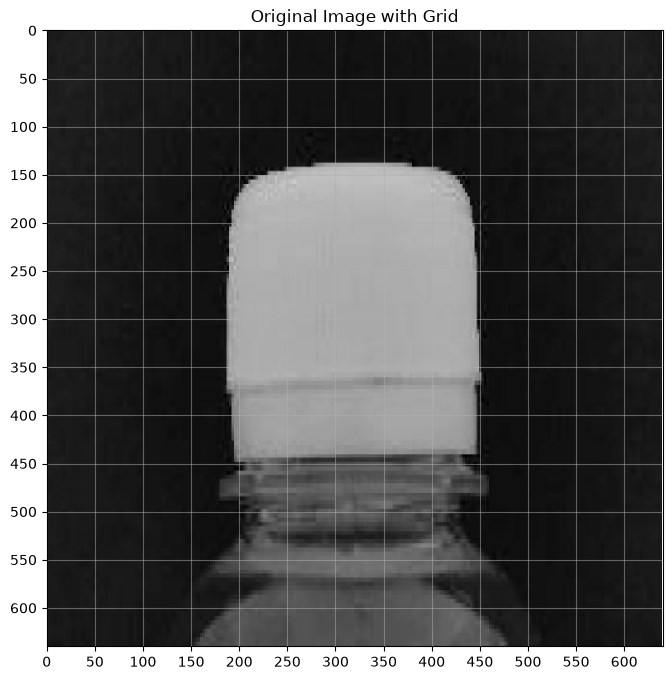

In [19]:
### BLOCK 5 — 좌표 그리드와 ROI 개선
### STEP 18: 50픽셀 간격 그리드
plt.figure(figsize=(10, 8))
plt.imshow(rgb_image)
plt.xticks(range(0, width + 1, 50))
plt.yticks(range(0, height + 1, 50))
plt.xlim(0, width)
plt.ylim(height, 0)
plt.grid(True, alpha=0.5)
plt.title("Original Image with Grid")
plt.show()

### STEP 19. 그리드를 보고 좌표를 다시 정합니다

이 좌표는 **설명용 예시**입니다. 위 그리드에 표시된 실제 병뚜껑 위치를 확인하여 바꾸세요. `x1`을 늘리면 ROI의 왼쪽 경계가 오른쪽으로 이동하고, `y1`을 늘리면 ROI의 위쪽 경계가 아래로 이동합니다.

In [20]:
### STEP 19: 개선할 좌표(예시값 — 실제 이미지에 맞게 변경)
x1, y1 = 170, 120
x2, y2 = 470, 500
print("수정한 ROI 좌표:", (x1, y1, x2, y2))

수정한 ROI 좌표: (170, 120, 470, 500)


### STEP 20. 수정한 x좌표를 다시 보정합니다

In [21]:
### STEP 20: 수정한 x좌표 범위 제한
x1 = max(0, min(x1, width))
x2 = max(0, min(x2, width))
print("최종 x좌표:", x1, x2)

최종 x좌표: 170 470


### STEP 21. 수정한 y좌표를 다시 보정합니다

In [22]:
### STEP 21: 수정한 y좌표 범위 제한
y1 = max(0, min(y1, height))
y2 = max(0, min(y2, height))
print("최종 y좌표:", y1, y2)

최종 y좌표: 120 500


### STEP 22. 수정한 좌표가 유효한지 다시 확인합니다

> **중요:** 여기서 좌표가 달라졌으므로 **다음 블록에서 ROI를 반드시 다시 잘라야** 합니다. 이전 `roi` 변수는 여전히 첫 번째 좌표로 만든 결과이기 때문입니다.

In [23]:
### STEP 22: 좌표 순서 검사
if x1 >= x2 or y1 >= y2:
    raise ValueError(f"수정한 ROI 좌표 오류: {(x1, y1, x2, y2)}")
print("수정한 ROI 좌표 검증 통과")

수정한 ROI 좌표 검증 통과


# BLOCK 6 — 수정한 ROI 다시 자르고 비교(Processing ② + QA)

### STEP 23. 수정 좌표로 ROI를 다시 자릅니다

In [24]:
### BLOCK 6 — 개선된 ROI 처리
### STEP 23: 새 좌표로 재추출
roi = image[y1:y2, x1:x2]
print("수정한 ROI Shape:", roi.shape)

수정한 ROI Shape: (380, 300, 3)


### STEP 24. 수정한 ROI를 화면에 출력합니다

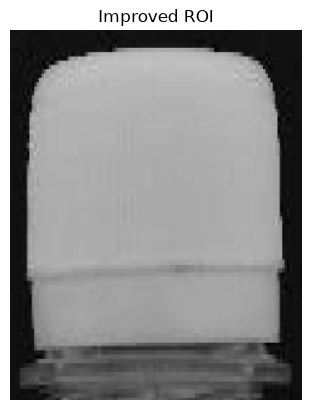

In [25]:
### STEP 24: 개선 ROI 시각화
roi_rgb = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
plt.imshow(roi_rgb)
plt.title("Improved ROI")
plt.axis("off")
plt.show()

### STEP 25. 첫 ROI와 수정한 ROI를 나란히 봅니다

**확인 질문:** (1) 병뚜껑 전체가 포함되나요? (2) 검사에 불필요한 배경이 줄었나요? (3) 배경이 줄면서 꼭 필요한 일부가 잘리지는 않았나요?

수정 결과가 아직 만족스럽지 않다면 **STEP 19~25만 다시 실행**하세요.

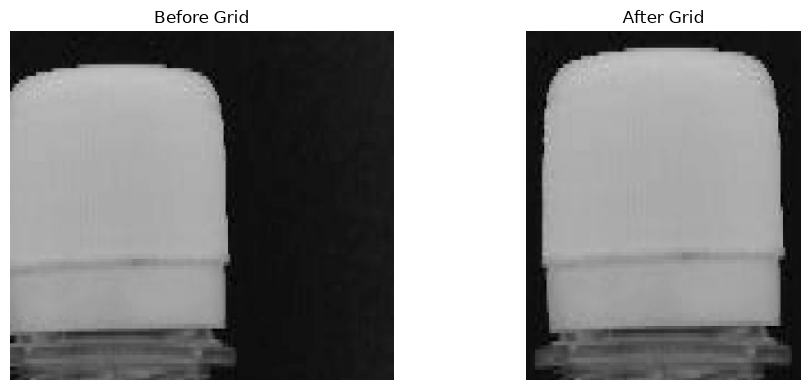

In [26]:
### STEP 25: 변경 전후 비교
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(roi_first, cv2.COLOR_BGR2RGB))
axes[0].set_title("Before Grid")
axes[1].imshow(roi_rgb)
axes[1].set_title("After Grid")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# BLOCK 7 — 원본 이미지에 최종 ROI 표시(Preview)

### STEP 26. Preview를 위해 원본을 복사합니다

직접 `image`에 사각형을 그리면 **원본 배열 자체가 변경될 수 있으므로** 복사본에 표시합니다.

In [27]:
### BLOCK 7 — Preview 생성
### STEP 26: 원본 보존
preview = image.copy()
print("Preview Shape:", preview.shape)

Preview Shape: (640, 640, 3)


### STEP 27. 복사본에 최종 ROI 사각형을 그립니다

`(0, 255, 0)`은 OpenCV의 **BGR 기준 녹색**, `3`은 선 두께입니다.

In [28]:
### STEP 27: ROI 위치 표시(녹색/BGR)
cv2.rectangle(preview, (x1, y1), (x2, y2), (0, 255, 0), 3)
print("사각형 표시 완료")

사각형 표시 완료


### STEP 28. Preview를 화면에 출력합니다

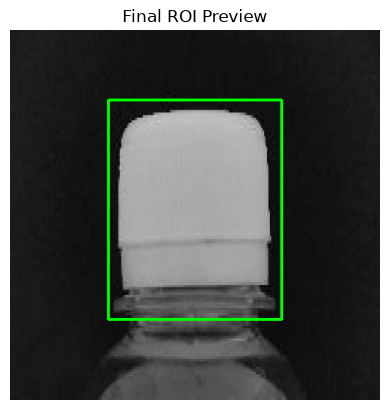

In [29]:
### STEP 28: Preview 시각화
preview_rgb = cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)
plt.imshow(preview_rgb)
plt.title("Final ROI Preview")
plt.axis("off")
plt.show()

### STEP 29. 원본·수정 ROI·Preview를 한 번에 비교합니다

- **Original:** 실제 원본은 그대로인가?
- **ROI:** 검사할 병뚜껑 영역만 추출되었는가?
- **Preview:** 원본에서 어디를 잘랐는지 사각형으로 보이는가?

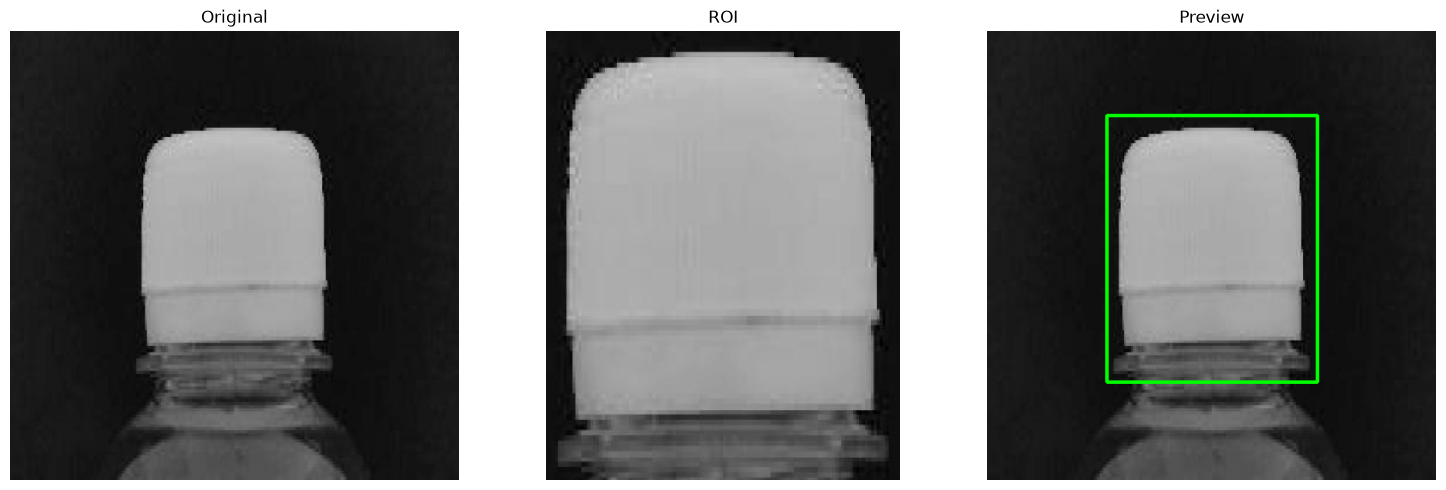

In [30]:
### STEP 29: 최종 화면 비교
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(
    axes, [rgb_image, roi_rgb, preview_rgb], ["Original", "ROI", "Preview"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# BLOCK 8 — 최종 파일 저장과 결과 검증(Output + QA)

> 여기서부터 최종 결과를 저장합니다. 처음 눈대중으로 잘랐던 ROI가 아닌, **그리드를 이용해 수정·확인한 ROI**를 저장합니다.

### STEP 30. 저장 폴더를 생성합니다

In [31]:
### BLOCK 8 — 최종 ROI 출력과 검증
### STEP 30: 출력 폴더 생성
output_dir.mkdir(parents=True, exist_ok=True)
print("출력 폴더 존재:", output_dir.is_dir())

출력 폴더 존재: True


### STEP 31. 저장 파일명을 만듭니다

In [32]:
### STEP 31: 두 파일 경로 설정
roi_path = output_dir / "sample01_roi.jpg"
preview_path = output_dir / "sample01_roi_preview.jpg"
print("ROI 파일:", roi_path)
print("Preview 파일:", preview_path)

ROI 파일: outputs/roi/sample01_roi.jpg
Preview 파일: outputs/roi/sample01_roi_preview.jpg


### STEP 32. 최종 ROI를 저장합니다

In [33]:
### STEP 32: ROI 이미지 저장
roi_saved = cv2.imwrite(str(roi_path), roi)
print("ROI 저장 성공:", roi_saved)

ROI 저장 성공: True


### STEP 33. 최종 Preview를 저장합니다

**주의:** 저장할 때는 `roi_rgb`와 `preview_rgb`가 아니라 **OpenCV가 사용하는 BGR 배열 `roi`, `preview`**를 저장합니다.

In [34]:
### STEP 33: Preview 이미지 저장
preview_saved = cv2.imwrite(str(preview_path), preview)
print("Preview 저장 성공:", preview_saved)

Preview 저장 성공: True


### STEP 34. 실제 파일 생성 여부를 검사합니다

`cv2.imwrite()`의 반환값과 파일 존재 여부를 확인합니다. 결과 이미지를 열어서 **최종 좌표로 잘린 것인지** 확인하는 습관도 중요합니다.

In [35]:
### STEP 34: 결과 파일 확인
print("ROI 파일 존재:", roi_path.is_file())
print("Preview 파일 존재:", preview_path.is_file())
if not (roi_saved and preview_saved):
    raise IOError("결과 이미지 저장에 실패했습니다.")

ROI 파일 존재: True
Preview 파일 존재: True


### STEP 35. 저장된 ROI 이미지를 다시 읽어 확인합니다

In [36]:
### STEP 35: 저장 결과 재검증
saved_roi = cv2.imread(str(roi_path))
if saved_roi is None:
    raise IOError(f"저장한 ROI를 읽지 못했습니다: {roi_path}")
print("저장된 ROI Shape:", saved_roi.shape)

저장된 ROI Shape: (380, 300, 3)


### STEP 36. 전체 실행 정보를 출력합니다

최종적으로 다음 두 파일이 존재해야 합니다.

```text
outputs/roi/
├── sample01_roi.jpg
└── sample01_roi_preview.jpg
```

In [37]:
### STEP 36: 최종 실행 결과
print("원본 크기:", image.shape)
print("최종 ROI 좌표:", (x1, y1, x2, y2))
print("ROI 크기:", roi.shape)
print("ROI 저장:", roi_path)
print("Preview 저장:", preview_path)

원본 크기: (640, 640, 3)
최종 ROI 좌표: (170, 120, 470, 500)
ROI 크기: (380, 300, 3)
ROI 저장: outputs/roi/sample01_roi.jpg
Preview 저장: outputs/roi/sample01_roi_preview.jpg


# BLOCK 9 — 원본 `.py`와 연결하고 직접 실행하기(Integration)

### STEP 37. Jupyter와 원본 `.py`의 차이를 확인합니다

원본 `src/03_roi_crop.py`는 **고정 좌표**로 이미지를 자르고 저장하는 완성 프로그램입니다.

| 구분 | 원본 `.py` | Jupyter 리뷰 |
|---|---|---|
| 이미지 읽기·오류 검사 | 있음 | 셀별로 분리해 확인 |
| ROI 범위 보정·슬라이싱 | 있음 | 숫자·이미지로 중간 결과 확인 |
| **좌표 그리드** | **없음** | **추가** |
| **좌표 수정 전·후 비교** | **없음** | **추가** |
| Preview 저장 | 있음 | 저장 전에 화면에서 확인 |
| 저장 결과 검증 | 간단한 경로 출력 | 반환값·파일 존재·재로드 확인 |

**중요:** Jupyter에서 `x1, y1, x2, y2`를 바꿨다고 원본 `src/03_roi_crop.py`의 숫자가 자동으로 변경되지는 않습니다. 확정한 좌표를 원본 `.py`의 좌표 4개에도 같은 값으로 수정해야 두 결과가 일치합니다.

### STEP 38. 원본 `.py`의 좌표를 확인합니다

`src/03_roi_crop.py`의 `x1`, `y1`, `x2`, `y2` 네 줄을 아래 출력 값에 맞게 변경합니다.

In [38]:
### BLOCK 9 — 통합 실행
### STEP 38: Notebook에서 확정한 좌표
print("원본 .py에 반영할 좌표:")
print(f"x1={x1}, y1={y1}, x2={x2}, y2={y2}")

원본 .py에 반영할 좌표:
x1=170, y1=120, x2=470, y2=500


### STEP 39. 터미널 또는 Jupyter에서 전체 `.py`를 실행합니다

터미널에서는 `python src/03_roi_crop.py`로 실행합니다. 아래 셀은 Jupyter에서 원본 코드를 외부 Python 프로세스로 실행하는 방법입니다.

**주의:** 원본 `.py`도 똑같은 `outputs/roi/` 경로로 저장하기 때문에 기존 Jupyter 결과 파일을 덮어쓸 수 있습니다. 좌표를 일치시켰다면 결과도 같습니다.

In [39]:
# STEP 39: Jupyter에서 원본 .py 실행(선택)
import sys
import subprocess
subprocess.run([sys.executable, "src/03_roi_crop.py"], check=True)

원본 크기 : (640, 640, 3)
ROI 좌표  : (170, 120, 470, 500)
ROI 크기  : (380, 300, 3)


CompletedProcess(args=['/home/user1/ai_vision/subject9_machinevision/.venv/bin/python', 'src/03_roi_crop.py'], returncode=0)

### STEP 40. 핵심 코드 리뷰 질문

1. `Path.cwd()`를 확인하는 이유는 무엇인가요?
2. `cv2.imread()`가 실패하면 무엇이 반환되나요?
3. `image.shape[:2]`에서 `height`가 먼저 나오는 이유는 무엇인가요?
4. `(x, y)` 좌표를 NumPy에서는 왜 `[y, x]`로 자르나요?
5. ROI를 자르기 전에 `min()`과 `max()`를 사용하는 이유는 무엇인가요?
6. 첫 ROI를 확인한 뒤 그리드가 필요한 이유는 무엇인가요?
7. **수정 좌표를 입력한 뒤 ROI를 다시 잘라야** 하는 이유는 무엇인가요?
8. `image.copy()` 없이 Preview에 사각형을 그리면 무엇이 달라질까요?
9. `roi`와 `preview`는 각각 어떤 목적으로 저장하나요?
10. Notebook에서 바꾼 좌표가 원본 `.py`에 자동으로 반영되지 않는 이유는 무엇인가요?

### STEP 41. 작은 코드 리뷰 Challenge

| 실험 | 직접 변경할 항목 | 확인할 결과 |
|---|---|---|
| A | `x1`을 20만큼 증가 | ROI 왼쪽 경계와 너비의 변화 |
| B | `y2`를 30만큼 감소 | ROI 아래쪽 경계와 높이의 변화 |
| C | `x2 = width + 100` | `max/min`으로 좌표가 제한되는지 |
| D | `x1`이 `x2`보다 커지도록 설정 | 좌표 예외가 발생하는지 |

**실습 방법:** STEP 19에서 좌표를 바꾸고 STEP 20~25를 다시 실행합니다. D 실험은 오류 발생을 확인한 뒤 정상 좌표로 되돌립니다. 마지막에 STEP 26~36으로 정상 결과를 저장합니다.

---

## 최종 정리 — 오늘 무엇을 이해했나요?

```text
이미지 읽기 → 이미지 크기·픽셀 구조 확인 → 첫 ROI 좌표 설정
→ 범위 제한과 오류 검사 → ROI 슬라이싱 → 첫 번째 결과 확인
→ X·Y 그리드로 좌표 분석 → ROI 좌표 재설정 → 개선한 ROI 재추출·비교
→ 원본 복사·Preview 표시 → ROI·Preview 저장 → 결과 검증
→ 원본 .py에서 재현
```